# Домашнее задание 9.1: Колебания стержня и цена диагональной массы

---

## 1. Постановка задачи и физико-математическая модель

Рассматриваются малые продольные упругие колебания однородного стержня постоянного единичного сечения на отрезке $x \in [0, 1]$.
В безразмерных переменных плотность и модуль упругости постоянны и равны единице:

$$
\rho(x) = 1, \qquad E(x) = 1, \qquad c = \sqrt{\frac{E}{\rho}} = 1.
$$

Динамическое волновое уравнение движения имеет вид:

$$
\rho \, u_{tt} = \partial_x (E \, u_x) \quad \Longleftrightarrow \quad u_{tt} = u_{xx}, \quad x \in (0, 1), \; t \gt 0.
$$

Концы стержня жестко закреплены (однородные граничные условия Дирихле):

$$
u(0, t) = 0, \qquad u(1, t) = 0.
$$

Начальные условия задают двухмодовую волновую форму при нулевой начальной скорости:

$$
u(x, 0) = \sin(\pi x) + 0.3 \sin(5\pi x), \qquad u_t(x, 0) = 0.
$$

Точное аналитическое решение задачи находится методом разделения переменных (рядом Фурье):

$$
u(x, t) = \sin(\pi x) \cos(\pi t) + 0.3 \sin(5\pi x) \cos(5\pi t).
$$

Первая гармоника имеет пространственную частоту $k_1 = \pi$, временную круговую частоту $\omega_1 = \pi$ и период $T_1 = 2.0$.  
Пятая гармоника имеет параметры $k_5 = 5\pi$, $\omega_5 = 5\pi$ и период $T_5 = 0.4$.

In [1]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display, Markdown

# Настройка эстетики графиков в академическом стиле
plt.rcParams.update({
    "figure.dpi": 130,
    "font.size": 10.5,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.8,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "gray"
})

# Цветовая палитра
BLUE   = "#0072B2"
ORANGE = "#D55E00"
GREEN  = "#009E73"
PURPLE = "#8B4BA5"
RED    = "#D52A2A"
GRAY   = "#555555"

def table(headers, rows):
    # Печать красиво отформатированной Markdown-таблицы с выравниванием колонок
    header_line = "| " + " | ".join(headers) + " |"
    sep_line = "| " + " | ".join("---:" if i > 0 else ":---" for i in range(len(headers))) + " |"
    row_lines = ["| " + " | ".join(str(val) for val in r) + " |" for r in rows]
    content = "\n\n" + "\n".join([header_line, sep_line] + row_lines) + "\n\n"
    display(Markdown(content))

## 2. Конечно-элементная аппроксимация и диагонализация массы

### 2.1. Вариационная (слабая) постановка
Умножая уравнение движения на пробную функцию $w(x) \in H_0^1(0, 1)$, удовлетворяющую $w(0) = w(1) = 0$, и интегрируя по частям, получаем слабую форму:

$$
\int_0^1 \rho \, u_{tt} w \, dx + \int_0^1 E \, u_x w_x \, dx = 0.
$$

Разобьем область $[0, 1]$ на $N$ одинаковых линейных элементов длины $h = 1/N$ с узлами $x_i = i h$, $i = 0, \dots, N$.
При кусочно-линейной базисной системе $\varphi_i(x)$ перемещение аппроксимируется как $u_h(x, t) = \sum_{i=0}^N U_i(t) \varphi_i(x)$.
Для одного элемента $e$ локальные матрицы массы и жесткости имеют вид:

$$
M_e = \frac{\rho_e h_e}{6} \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix} = \frac{h}{6} \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}, \qquad
K_e = \frac{E_e}{h_e} \begin{pmatrix} 1 & -1 \\ -1 & 1 \end{pmatrix} = \frac{1}{h} \begin{pmatrix} 1 & -1 \\ -1 & 1 \end{pmatrix}.
$$

### 2.2. Процедура диагонализации (Mass Lumping)
В точном соответствии с регламентом задания:
1. Собираем глобальные матрицы $M_{\mathrm{full}}$ и $K_{\mathrm{full}}$ размера $(N+1) \times (N+1)$ по всем узлам сетки.
2. Диагональную матрицу масс $M_{L, \mathrm{full}}$ получаем построчным суммированием элементов полной матрицы:

   $$
   M_{L, \mathrm{full}} = \operatorname{diag}\left( M_{\mathrm{full}} \, \mathbf{1} \right).
   $$

   Для любого внутреннего узла $i \in \{1, \dots, N-1\}$ сумма строки равна $\frac{h}{6} + \frac{4h}{6} + \frac{h}{6} = h$.
3. Исключаем закрепленные граничные степени свободы $U_0 = 0$ и $U_N = 0$, переходя к редуцированным матрицам $M$, $M_L$ и $K$ на внутренних степенях свободы $i = 1, \dots, N-1$ (размер $(N-1) \times (N-1)$).

### 2.3. Скоростной метод Верле (Velocity Verlet)
Полученная полудискретная система ОДУ имеет вид:

$$
M_{\ast} \ddot{U} + K U = 0, \quad M_{\ast} \in \{M_L, M\}.
$$

Интегрирование по времени выполняется симплектическим методом Верле второго порядка:

$$
a^n = -M_{\ast}^{-1} K U^n,
$$

$$
V^{n+1/2} = V^n + \frac{\Delta t}{2} a^n,
$$

$$
U^{n+1} = U^n + \Delta t \, V^{n+1/2},
$$

$$
a^{n+1} = -M_{\ast}^{-1} K U^{n+1},
$$

$$
V^{n+1} = V^{n+1/2} + \frac{\Delta t}{2} a^{n+1}.
$$

Для согласованной массы $M_{\ast} = M$ действие оператора $M^{-1}$ находится решением СЛАУ с помощью факторизации Холецкого (выполняемой один раз на этапе препроцессинга).

Дискретная механическая энергия системы:

$$
\mathcal{H}_h(t) = \frac{1}{2} V^T M_{\ast} V + \frac{1}{2} U^T K U.
$$

In [2]:
def assemble_fem_matrices(N):
    # Сборка матриц жесткости и массы (согласованной и диагональной)
    h = 1.0 / N
    Me = (h / 6.0) * np.array([[2.0, 1.0], [1.0, 2.0]])
    Ke = (1.0 / h) * np.array([[1.0, -1.0], [-1.0, 1.0]])

    # Сборка на полной сетке
    M_full = np.zeros((N + 1, N + 1))
    K_full = np.zeros((N + 1, N + 1))

    for e in range(N):
        idx = [e, e + 1]
        M_full[np.ix_(idx, idx)] += Me
        K_full[np.ix_(idx, idx)] += Ke

    # Диагонализация массы построчным суммированием на полной сетке
    M_L_full = np.diag(np.sum(M_full, axis=1))

    # Исключение закрепленных степеней свободы (границы 0 и N)
    M_consist = M_full[1:-1, 1:-1]
    M_lump = M_L_full[1:-1, 1:-1]
    K = K_full[1:-1, 1:-1]
    x_nodes = np.linspace(0.0, 1.0, N + 1)
    
    return K, M_consist, M_lump, x_nodes

def exact_solution(x, t):
    # Точное аналитическое решение волнового уравнения
    return np.sin(np.pi * x) * np.cos(np.pi * t) + 0.3 * np.sin(5.0 * np.pi * x) * np.cos(5.0 * np.pi * t)

def simulate_verlet(N, mass_type='lumped', dt=None, t_max=2.5, u0_perturb=None):
    # Численное интегрирование уравнений движения скоростным методом Верле
    h = 1.0 / N
    K, M_consist, M_lump, x_nodes = assemble_fem_matrices(N)
    x_int = x_nodes[1:-1]
    
    if mass_type == 'lumped':
        M_star = M_lump
        inv_mass_diag = 1.0 / np.diag(M_lump)
        def solve_acc(U):
            return - inv_mass_diag * (K @ U)
    elif mass_type == 'consistent':
        M_star = M_consist
        cho = la.cho_factor(M_consist)
        def solve_acc(U):
            return - la.cho_solve(cho, K @ U)
    else:
        raise ValueError("mass_type must be 'lumped' or 'consistent'")

    if dt is None:
        dt = 0.5 * h

    n_steps = int(np.round(t_max / dt))

    # Начальные условия
    U = exact_solution(x_int, 0.0)
    if u0_perturb is not None:
        U = U + u0_perturb
    V = np.zeros_like(U)

    # Начальное ускорение
    a = solve_acc(U)

    # Начальная энергия
    H0 = 0.5 * (V @ (M_star @ V)) + 0.5 * (U @ (K @ U))

    times = [0.0]
    energies = [H0]
    displacements = [U.copy()]
    
    for step in range(n_steps):
        V_half = V + 0.5 * dt * a
        U = U + dt * V_half
        a = solve_acc(U)
        V = V_half + 0.5 * dt * a

        t_curr = (step + 1) * dt
        H_curr = 0.5 * (V @ (M_star @ V)) + 0.5 * (U @ (K @ U))

        times.append(t_curr)
        energies.append(H_curr)
        displacements.append(U.copy())

    return {
        'times': np.array(times),
        'energies': np.array(energies),
        'displacements': displacements,
        'x_nodes': x_nodes,
        'dt': dt,
        'h': h,
        'H0': H0,
        'K': K,
        'M_star': M_star
    }

---
## 3. 🟢 Зелёный уровень: Колебания стержня с диагональной массой

В базовой части исследуется поведение схемы с диагональной массой $M_L$ при шаге $\Delta t = 0.5 h$ на трех сетках: $N = 40, 80, 160$.
Шаг по времени подобран так, что контрольные моменты времени $t = 0.25$, $t = 0.75$ и $t = 2.25$ в точности попадают на узлы временной сетки:
- $N = 40$: $h = 0.025$, $\Delta t = 0.0125$ (шаги: 20, 60, 180)
- $N = 80$: $h = 0.0125$, $\Delta t = 0.00625$ (шаги: 40, 120, 360)
- $N = 160$: $h = 0.00625$, $\Delta t = 0.003125$ (шаги: 80, 240, 720)

In [3]:
target_times = [0.25, 0.75, 2.25]
grids = [40, 80, 160]
results_green = {}

for N in grids:
    res = simulate_verlet(N, mass_type='lumped', dt=None, t_max=2.5)
    results_green[N] = res

headers_green = [
    "$N$", "$h$", r"$\Delta t$", "$t$",
    r"$e_\infty = \max_i \lvert U_i - u(x_i, t)\rvert$", "Порядок $p$",
    r"$[\mathcal{H}_h(t) - \mathcal{H}_h(0)] / \mathcal{H}_h(0)$"
]

rows_green = []
err_dict = {t_val: [] for t_val in target_times}

for N in grids:
    res = results_green[N]
    h_val = res['h']
    dt_val = res['dt']
    x_int = res['x_nodes'][1:-1]
    
    for t_val in target_times:
        step_idx = int(np.round(t_val / dt_val))
        U_sim = res['displacements'][step_idx]
        U_exact = exact_solution(x_int, t_val)
        err = np.max(np.abs(U_sim - U_exact))
        err_dict[t_val].append(err)
        
        H_curr = res['energies'][step_idx]
        dE = (H_curr - res['H0']) / res['H0']
        
        if len(err_dict[t_val]) > 1:
            prev_err = err_dict[t_val][-2]
            order = np.log2(prev_err / err)
            order_str = f"**{order:.2f}**"
        else:
            order_str = "—"
            
        rows_green.append([
            N,
            f"{h_val:.5f}",
            f"{dt_val:.5f}",
            f"{t_val:.2f}",
            f"`{err:.4e}`",
            order_str,
            f"`{dE:+.4e}`"
        ])

display(Markdown("### 3.1. Таблица сеточной сходимости и изменения энергии"))
table(headers_green, rows_green)

### 3.1. Таблица сеточной сходимости и изменения энергии



| $N$ | $h$ | $\Delta t$ | $t$ | $e_\infty = \max_i \lvert U_i - u(x_i, t)\rvert$ | Порядок $p$ | $[\mathcal{H}_h(t) - \mathcal{H}_h(0)] / \mathcal{H}_h(0)$ |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| 40 | 0.02500 | 0.01250 | 0.25 | `4.0724e-03` | — | `-3.2164e-03` |
| 40 | 0.02500 | 0.01250 | 0.75 | `1.2669e-02` | — | `-3.7136e-03` |
| 40 | 0.02500 | 0.01250 | 2.25 | `3.3737e-02` | — | `-2.2420e-03` |
| 80 | 0.01250 | 0.00625 | 0.25 | `1.0235e-03` | **1.99** | `-8.3761e-04` |
| 80 | 0.01250 | 0.00625 | 0.75 | `3.0990e-03` | **2.03** | `-8.6907e-04` |
| 80 | 0.01250 | 0.00625 | 2.25 | `9.0377e-03` | **1.90** | `-7.7477e-04` |
| 160 | 0.00625 | 0.00313 | 0.25 | `2.5621e-04` | **2.00** | `-2.1152e-04` |
| 160 | 0.00625 | 0.00313 | 0.75 | `7.7041e-04` | **2.01** | `-2.1349e-04` |
| 160 | 0.00625 | 0.00313 | 2.25 | `2.2952e-03` | **1.98** | `-2.0758e-04` |



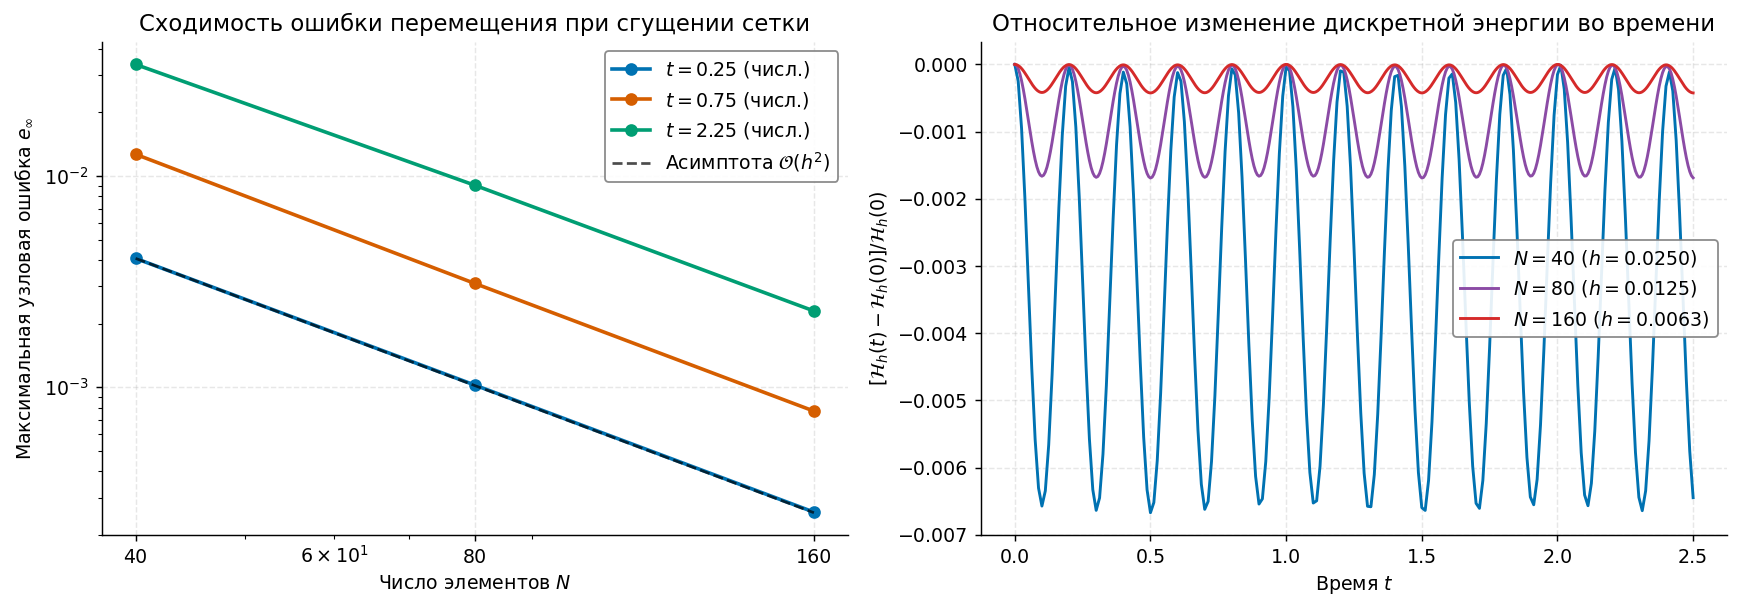

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# 1. Сходимость ошибки
colors_t = [BLUE, ORANGE, GREEN]
for idx, t_val in enumerate(target_times):
    axes[0].plot(grids, err_dict[t_val], 'o-', color=colors_t[idx],
                 label=f'$t = {t_val}$ (числ.)', lw=2, markersize=6)

# Теоретическая асимптота O(h^2)
ref_h2 = [err_dict[0.25][0] * (40 / N)**2 for N in grids]
axes[0].plot(grids, ref_h2, 'k--', label=r'Асимптота $\mathcal{O}(h^2)$', alpha=0.7, lw=1.5)

axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xticks(grids)
axes[0].set_xticklabels([str(n) for n in grids])
axes[0].set_xlabel('Число элементов $N$')
axes[0].set_ylabel(r'Максимальная узловая ошибка $e_\infty$')
axes[0].set_title('Сходимость ошибки перемещения при сгущении сетки')
axes[0].legend()

# 2. Относительное изменение энергии
grid_colors = [BLUE, PURPLE, RED]
for idx, N in enumerate(grids):
    res = results_green[N]
    rel_energy = (res['energies'] - res['H0']) / res['H0']
    axes[1].plot(res['times'], rel_energy, color=grid_colors[idx],
                 label=f'$N = {N}$ ($h = {res["h"]:.4f}$)', lw=1.6)

axes[1].set_xlabel('Время $t$')
axes[1].set_ylabel(r'$[\mathcal{H}_h(t) - \mathcal{H}_h(0)] / \mathcal{H}_h(0)$')
axes[1].set_title('Относительное изменение дискретной энергии во времени')
axes[1].legend()

plt.tight_layout()
plt.show()

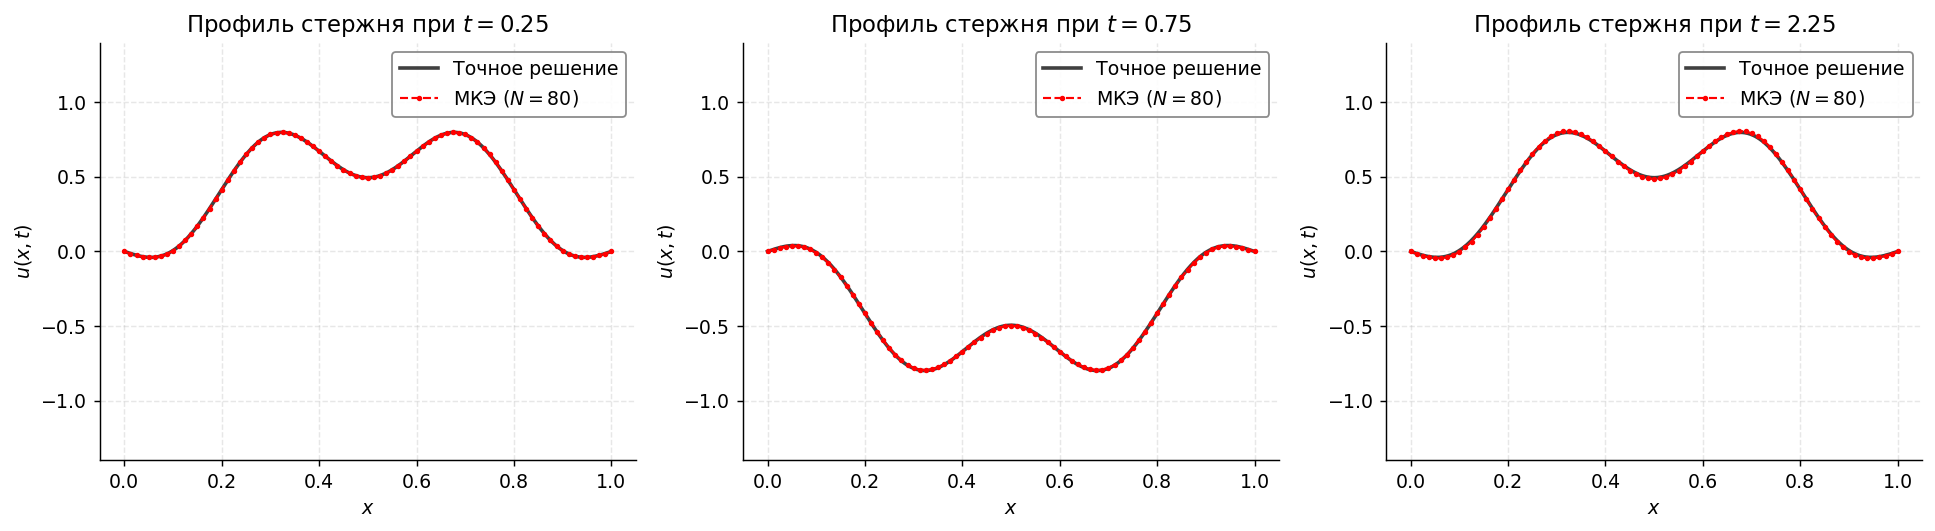

In [5]:
N_plot = 80
res_plot = results_green[N_plot]
x_dense = np.linspace(0, 1, 400)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for i, t_val in enumerate(target_times):
    step_idx = int(np.round(t_val / res_plot['dt']))
    U_nodes = np.zeros(N_plot + 1)
    U_nodes[1:-1] = res_plot['displacements'][step_idx]
    
    axes[i].plot(x_dense, exact_solution(x_dense, t_val), 'k-', lw=2, label='Точное решение', alpha=0.75)
    axes[i].plot(res_plot['x_nodes'], U_nodes, 'r.--', markersize=4, lw=1.2, label=f'МКЭ ($N={N_plot}$)')
    axes[i].set_title(f'Профиль стержня при $t = {t_val}$')
    axes[i].set_xlabel('$x$')
    axes[i].set_ylabel('$u(x, t)$')
    axes[i].set_ylim(-1.4, 1.4)
    axes[i].legend()

plt.tight_layout()
plt.show()

In [6]:
# Анимация колебаний стержня (наложение численного решения на точное)
N_anim = 80
res_anim = results_green[N_anim]

fig_anim, ax_anim = plt.subplots(figsize=(8, 4.5))
ax_anim.set_xlim(0, 1)
ax_anim.set_ylim(-1.45, 1.45)
ax_anim.set_xlabel('$x$')
ax_anim.set_ylabel('$u(x, t)$')
title_anim = ax_anim.set_title('')

x_plot_dense = np.linspace(0, 1, 300)
line_exact, = ax_anim.plot([], [], 'k-', lw=2.2, label='Точное аналитическое решение', alpha=0.75)
line_fem, = ax_anim.plot([], [], 'r.-', lw=1.5, markersize=4, label=f'МКЭ Верле ($M_L$, $N={N_anim}$)')
ax_anim.legend(loc='upper right')

# 60 кадров на интервале t in [0, 2.0] (один полный период 1-й моды)
n_frames = 60
frame_steps = np.linspace(0, int(np.round(2.0 / res_anim['dt'])), n_frames, dtype=int)

def init_anim():
    line_exact.set_data([], [])
    line_fem.set_data([], [])
    title_anim.set_text('')
    return line_exact, line_fem, title_anim

def update_anim(frame):
    step = frame_steps[frame]
    t_curr = res_anim['times'][step]
    
    U_full = np.zeros(N_anim + 1)
    U_full[1:-1] = res_anim['displacements'][step]
    
    line_exact.set_data(x_plot_dense, exact_solution(x_plot_dense, t_curr))
    line_fem.set_data(res_anim['x_nodes'], U_full)
    title_anim.set_text(f'Колебания стержня: $t = {t_curr:.3f}$ с (период первой моды $T_1 = 2.0$)')
    return line_exact, line_fem, title_anim

anim = animation.FuncAnimation(fig_anim, update_anim, init_func=init_anim, frames=n_frames, interval=50, blit=True)
plt.close(fig_anim)

display(HTML("<h4>Анимация колебаний стержня с диагональной массой:</h4>"))
display(HTML(anim.to_jshtml()))

### 3.2. Ответ на ключевой вопрос зеленого уровня 🟢

> **Вопрос:** *Означает ли хорошее сохранение энергии, что фаза колебаний тоже вычислена правильно?*

**Ответ: Нет, не означает.**

1. **Симплектичность против фазовой точности:**  
   Метод Верле является **симплектическим интегратором**. Для гамильтоновых систем он строго сохраняет близкий модифицированный (теневой) гамильтониан $\widetilde{\mathcal{H}} = \mathcal{H} + \mathcal{O}(\Delta t^2)$. В силу этого вычисленная энергия совершает ограниченные периодические колебания порядка $\mathcal{O}(\Delta t^2)$ без монотонного затухания или амплитудного взрыва.
2. **Линейное накопление фазовой ошибки:**  
   Дискретизация по пространству (МКЭ) и по времени (схема Верле) искажают собственные частоты системы: расчетная сеточная частота $\omega_h$ отличается от непрерывной $\omega$. Погрешность по фазе накапливается со временем линейно:

   $$
   \Delta \varphi(t) = \lvert \omega_h - \omega\rvert \, t.
   $$

3. **Физический эффект:**  
   При достаточно длительном интегрировании ($t \sim \pi / \lvert \omega_h - \omega\rvert$) численная волна отстанет от истинной настолько, что окажется в полной противофазе с ней ($U_h(t) \approx -u_{\mathrm{exact}}(t)$), а максимальная узловая ошибка достигнет удвоенной амплитуды $e_\infty \approx 2 \max \lvert u\rvert$. При этом полная механическая энергия $\mathcal{H}_h(t)$ останется практически неизменной (с точностью до долей процента)!
   
*Вывод:* Сохранение энергии гарантирует **амплитудную устойчивость**, но ничего не говорит о точности вычисления фазы.

---
## 4. 🟡 Жёлтый уровень: Согласованная vs диагональная масса, спектральный анализ и устойчивость

На продвинутом уровне рассматривается влияние структуры матрицы масс:
- **Согласованная матрица** $M$ (Consistent Mass): полученная точным интегрированием базисных функций $\int \varphi_i \varphi_j dx$.
- **Диагональная матрица** $M_L$ (Lumped Mass): полученная процедурой сжатия массы по строкам на полной сетке.

Для обеих формулировок решается обобщенная задача на собственные значения:

$$
K z_j = \omega_{h, j}^2 \, M_{\ast} z_j, \qquad M_{\ast} \in \{M, M_L\}, \quad j = 1, \dots, N-1.
$$

Критический шаг интегрирования по времени определяется максимальной собственной частотой системы:

$$
\Delta t_{\mathrm{crit}} = \frac{2}{\omega_{h, \max}}.
$$

In [7]:
N_yellow = 40
h_yellow = 1.0 / N_yellow
K_y, M_consist_y, M_lump_y, x_nodes_y = assemble_fem_matrices(N_yellow)
Ndof_y = N_yellow - 1

# Решение обобщенной задачи на собственные значения
evals_L, evecs_L = la.eigh(K_y, M_lump_y)
evals_C, evecs_C = la.eigh(K_y, M_consist_y)

omega_L = np.sqrt(evals_L)
omega_C = np.sqrt(evals_C)
j_modes = np.arange(1, Ndof_y + 1)
omega_exact = j_modes * np.pi

# Предельный шаг Верле
omega_max_L = omega_L[-1]
omega_max_C = omega_C[-1]
dt_crit_L = 2.0 / omega_max_L
dt_crit_C = 2.0 / omega_max_C

# Нормировка собственных векторов высшей частоты для теста возмущений
z_max_L = evecs_L[:, -1] / np.max(np.abs(evecs_L[:, -1]))
z_max_C = evecs_C[:, -1] / np.max(np.abs(evecs_C[:, -1]))

headers_spec = [
    "Мода $j$",
    r"$\omega_{\mathrm{exact}} = j\pi$",
    r"$\omega_{h, L}$ ($M_L$)",
    r"Погрешность $M_L$",
    r"$\omega_{h, C}$ ($M$)",
    r"Погрешность $M$"
]

rows_spec = []
for j in range(1, 11):
    w_ex = omega_exact[j-1]
    w_l = omega_L[j-1]
    w_c = omega_C[j-1]
    err_l = (w_l - w_ex) / w_ex * 100.0
    err_c = (w_c - w_ex) / w_ex * 100.0
    rows_spec.append([
        j,
        f"{w_ex:.5f}",
        f"{w_l:.5f}",
        f"`{err_l:+.4f}%`",
        f"{w_c:.5f}",
        f"`{err_c:+.4f}%`"
    ])

rows_spec.append([
    f"**Макс. ({Ndof_y})**",
    f"{omega_exact[-1]:.3f}",
    f"**{omega_max_L:.3f}**",
    f"`{(omega_max_L - omega_exact[-1]) / omega_exact[-1] * 100.0:+.2f}%`",
    f"**{omega_max_C:.3f}**",
    f"`{(omega_max_C - omega_exact[-1]) / omega_exact[-1] * 100.0:+.2f}%`"
])

display(Markdown("### 4.1. Сравнение собственных частот и предельных шагов Верле ($N=40$)"))
table(headers_spec, rows_spec)

# Итог по критическим шагам интегрирования с аккуратным рендерингом LaTeX
summary_lines = [
    f"- **Диагональная масса ($M_L$):** $\\omega_{{h, \\max}} = {omega_max_L:.4f}$, критический шаг: $\\Delta t_{{\\mathrm{{crit}}, L}} = {dt_crit_L:.6f} \\approx 1.0008 \\, h$.",
    f"- **Согласованная масса ($M$):** $\\omega_{{h, \\max}} = {omega_max_C:.4f}$, критический шаг: $\\Delta t_{{\\mathrm{{crit}}, C}} = {dt_crit_C:.6f} \\approx 0.5787 \\, h \\approx h / \\sqrt{{3}}$."
]
display(Markdown("\n".join(summary_lines)))

### 4.1. Сравнение собственных частот и предельных шагов Верле ($N=40$)



| Мода $j$ | $\omega_{\mathrm{exact}} = j\pi$ | $\omega_{h, L}$ ($M_L$) | Погрешность $M_L$ | $\omega_{h, C}$ ($M$) | Погрешность $M$ |
| :--- | ---: | ---: | ---: | ---: | ---: |
| 1 | 3.14159 | 3.14079 | `-0.0257%` | 3.14240 | `+0.0257%` |
| 2 | 6.28319 | 6.27673 | `-0.1028%` | 6.28965 | `+0.1028%` |
| 3 | 9.42478 | 9.40299 | `-0.2312%` | 9.44659 | `+0.2315%` |
| 4 | 12.56637 | 12.51476 | `-0.4107%` | 12.61811 | `+0.4117%` |
| 5 | 15.70796 | 15.60723 | `-0.6413%` | 15.80908 | `+0.6437%` |
| 6 | 18.84956 | 18.67563 | `-0.9227%` | 19.02442 | `+0.9277%` |
| 7 | 21.99115 | 21.71524 | `-1.2547%` | 22.26905 | `+1.2637%` |
| 8 | 25.13274 | 24.72136 | `-1.6368%` | 25.54793 | `+1.6520%` |
| 9 | 28.27433 | 27.68936 | `-2.0689%` | 28.86604 | `+2.0927%` |
| 10 | 31.41593 | 30.61467 | `-2.5505%` | 32.22831 | `+2.5859%` |
| **Макс. (39)** | 122.522 | **79.938** | `-34.76%` | **138.244** | `+12.83%` |



- **Диагональная масса ($M_L$):** $\omega_{h, \max} = 79.9383$, критический шаг: $\Delta t_{\mathrm{crit}, L} = 0.025019 \approx 1.0008 \, h$.
- **Согласованная масса ($M$):** $\omega_{h, \max} = 138.2443$, критический шаг: $\Delta t_{\mathrm{crit}, C} = 0.014467 \approx 0.5787 \, h \approx h / \sqrt{3}$.

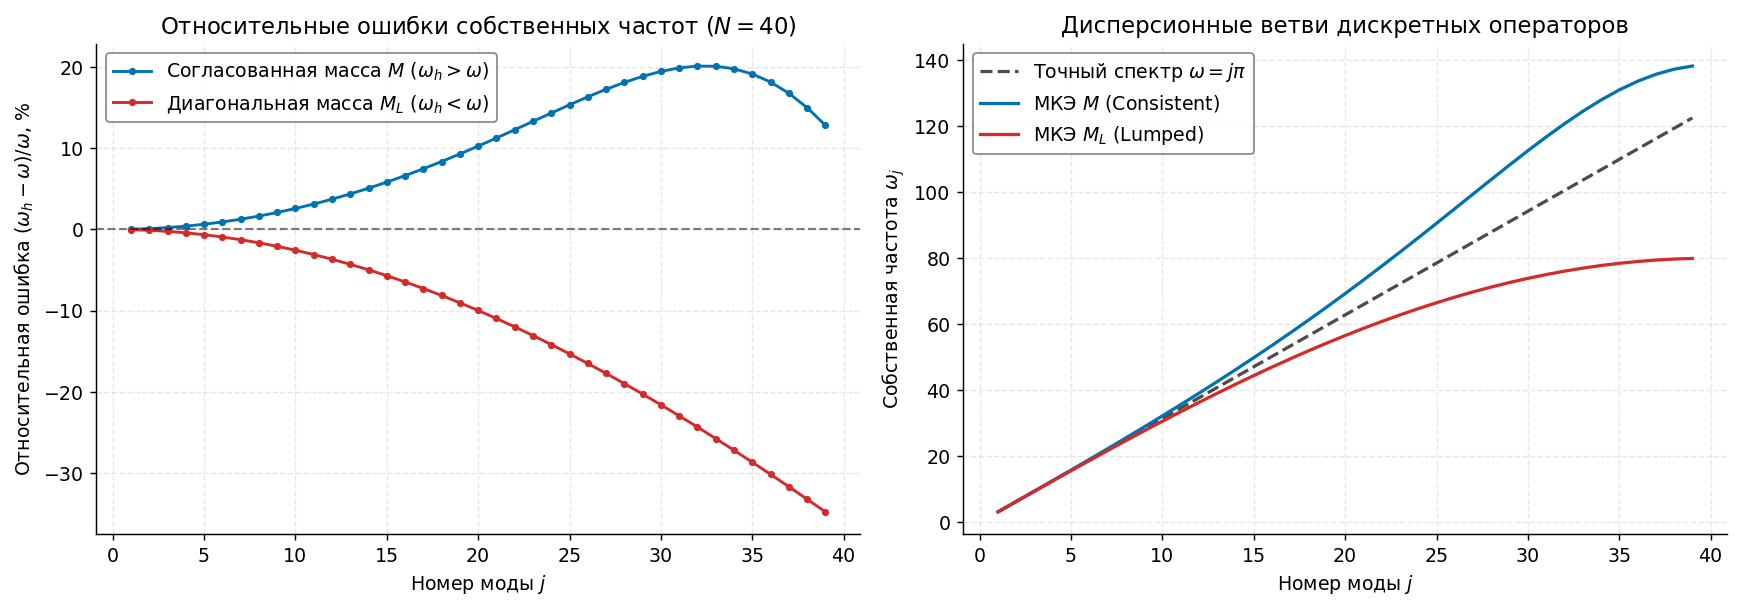

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

rel_err_L = (omega_L - omega_exact) / omega_exact * 100.0
rel_err_C = (omega_C - omega_exact) / omega_exact * 100.0

# 1. Относительные ошибки частот
axes[0].plot(j_modes, rel_err_C, '.-', color=BLUE, label=r'Согласованная масса $M$ ($\omega_h > \omega$)', lw=1.6)
axes[0].plot(j_modes, rel_err_L, '.-', color=RED, label=r'Диагональная масса $M_L$ ($\omega_h < \omega$)', lw=1.6)
axes[0].axhline(0, color='k', linestyle='--', alpha=0.5, lw=1.2)
axes[0].set_xlabel('Номер моды $j$')
axes[0].set_ylabel(r'Относительная ошибка $(\omega_h - \omega)/\omega$, %')
axes[0].set_title(r'Относительные ошибки собственных частот ($N=40$)')
axes[0].legend()

# 2. Дисперсионные ветви
axes[1].plot(j_modes, omega_exact, 'k--', label=r'Точный спектр $\omega = j\pi$', alpha=0.7, lw=1.8)
axes[1].plot(j_modes, omega_C, '-', color=BLUE, label=r'МКЭ $M$ (Consistent)', lw=1.8)
axes[1].plot(j_modes, omega_L, '-', color=RED, label=r'МКЭ $M_L$ (Lumped)', lw=1.8)
axes[1].set_xlabel('Номер моды $j$')
axes[1].set_ylabel(r'Собственная частота $\omega_j$')
axes[1].set_title(r'Дисперсионные ветви дискретных операторов')
axes[1].legend()

plt.tight_layout()
plt.show()

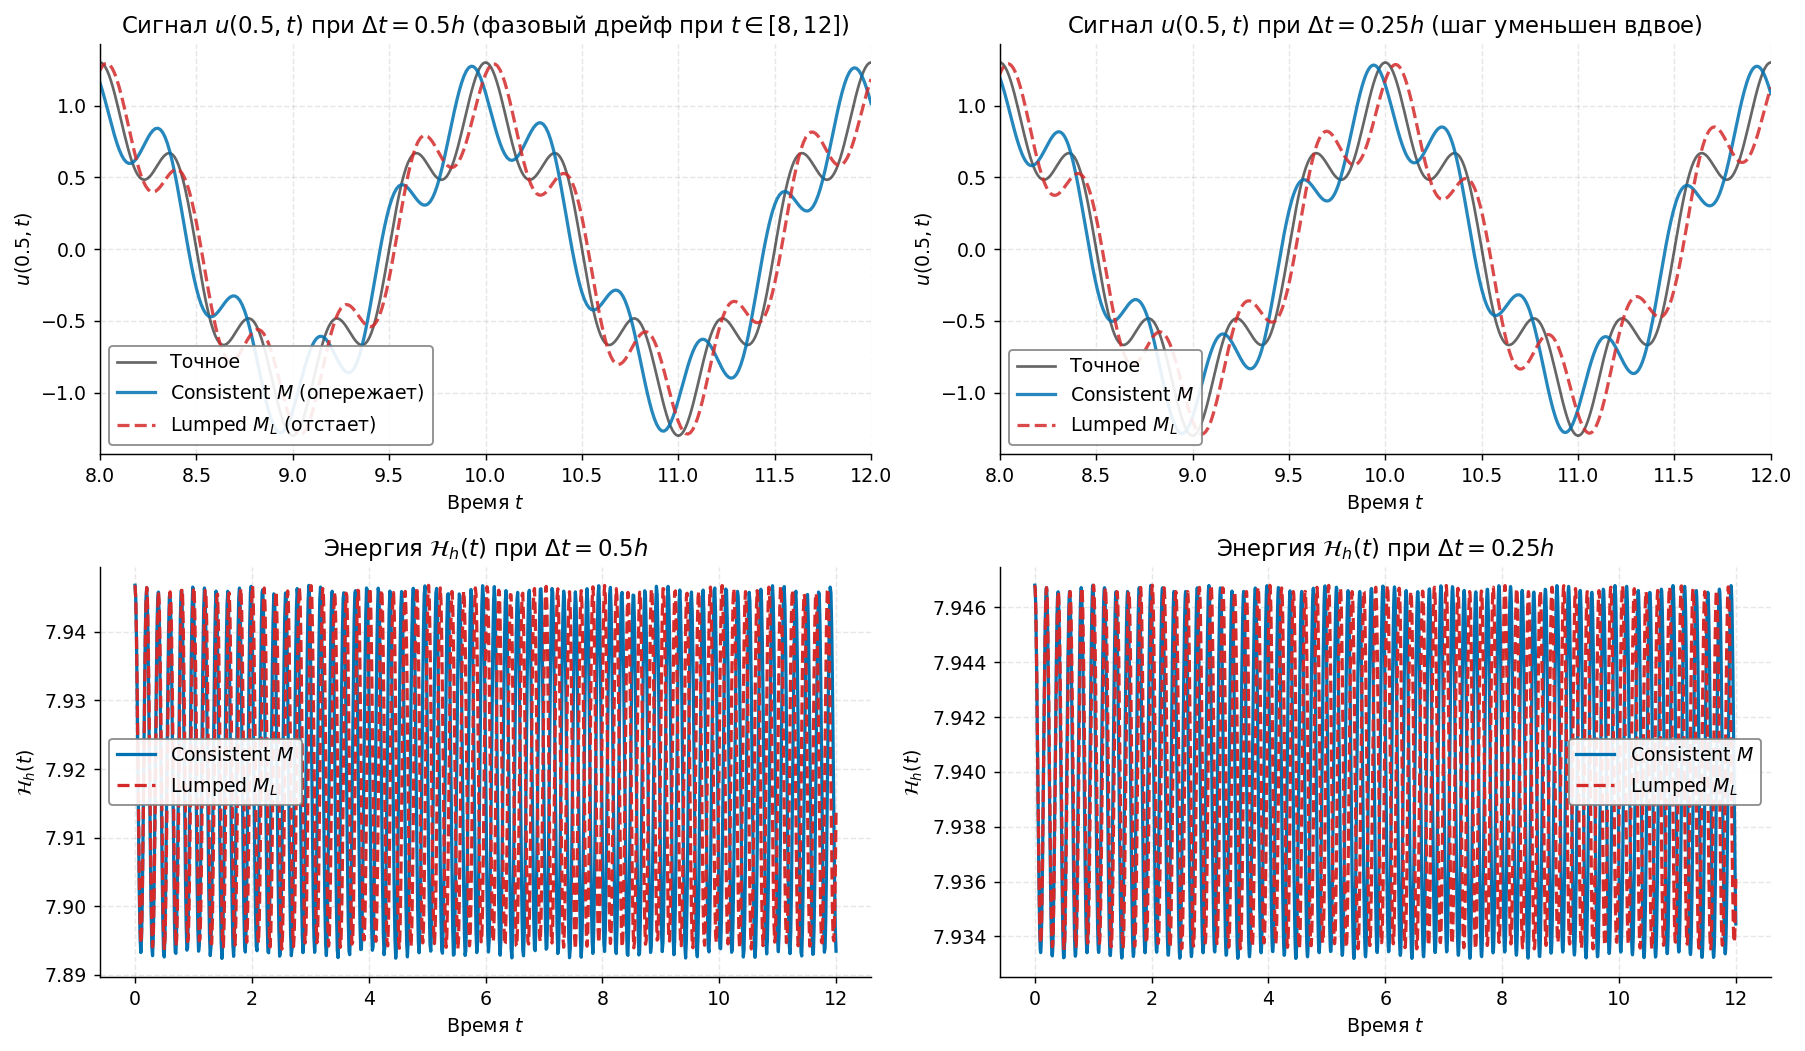

In [9]:
t_long = 12.0
dt_stable_1 = 0.5 * h_yellow   # 0.0125
dt_stable_2 = 0.25 * h_yellow  # 0.00625

center_idx = N_yellow // 2 - 1

sim_L_dt1 = simulate_verlet(N_yellow, 'lumped', dt=dt_stable_1, t_max=t_long)
sim_L_dt2 = simulate_verlet(N_yellow, 'lumped', dt=dt_stable_2, t_max=t_long)

sim_C_dt1 = simulate_verlet(N_yellow, 'consistent', dt=dt_stable_1, t_max=t_long)
sim_C_dt2 = simulate_verlet(N_yellow, 'consistent', dt=dt_stable_2, t_max=t_long)

t_exact_dense = np.linspace(0, t_long, 1200)
u_exact_center = exact_solution(0.5, t_exact_dense)

fig, axes = plt.subplots(2, 2, figsize=(14, 8.2))

# 1. Сигналы при dt = 0.5 h
u_L_dt1 = [u_arr[center_idx] for u_arr in sim_L_dt1['displacements']]
u_C_dt1 = [u_arr[center_idx] for u_arr in sim_C_dt1['displacements']]

axes[0, 0].plot(t_exact_dense, u_exact_center, 'k-', lw=1.5, alpha=0.6, label='Точное')
axes[0, 0].plot(sim_C_dt1['times'], u_C_dt1, '-', color=BLUE, label='Consistent $M$ (опережает)', alpha=0.85)
axes[0, 0].plot(sim_L_dt1['times'], u_L_dt1, '--', color=RED, label='Lumped $M_L$ (отстает)', alpha=0.85)
axes[0, 0].set_xlim(8.0, 12.0)
axes[0, 0].set_xlabel('Время $t$')
axes[0, 0].set_ylabel('$u(0.5, t)$')
axes[0, 0].set_title(r'Сигнал $u(0.5, t)$ при $\Delta t = 0.5 h$ (фазовый дрейф при $t \in [8, 12]$)')
axes[0, 0].legend(loc='lower left')

# 2. Сигналы при dt = 0.25 h
u_L_dt2 = [u_arr[center_idx] for u_arr in sim_L_dt2['displacements']]
u_C_dt2 = [u_arr[center_idx] for u_arr in sim_C_dt2['displacements']]

axes[0, 1].plot(t_exact_dense, u_exact_center, 'k-', lw=1.5, alpha=0.6, label='Точное')
axes[0, 1].plot(sim_C_dt2['times'], u_C_dt2, '-', color=BLUE, label='Consistent $M$', alpha=0.85)
axes[0, 1].plot(sim_L_dt2['times'], u_L_dt2, '--', color=RED, label='Lumped $M_L$', alpha=0.85)
axes[0, 1].set_xlim(8.0, 12.0)
axes[0, 1].set_xlabel('Время $t$')
axes[0, 1].set_ylabel('$u(0.5, t)$')
axes[0, 1].set_title(r'Сигнал $u(0.5, t)$ при $\Delta t = 0.25 h$ (шаг уменьшен вдвое)')
axes[0, 1].legend(loc='lower left')

# 3. Полная энергия при dt = 0.5 h
axes[1, 0].plot(sim_C_dt1['times'], sim_C_dt1['energies'], color=BLUE, label=r'Consistent $M$')
axes[1, 0].plot(sim_L_dt1['times'], sim_L_dt1['energies'], '--', color=RED, label=r'Lumped $M_L$')
axes[1, 0].set_xlabel('Время $t$')
axes[1, 0].set_ylabel(r'$\mathcal{H}_h(t)$')
axes[1, 0].set_title(r'Энергия $\mathcal{H}_h(t)$ при $\Delta t = 0.5 h$')
axes[1, 0].legend()

# 4. Полная энергия при dt = 0.25 h
axes[1, 1].plot(sim_C_dt2['times'], sim_C_dt2['energies'], color=BLUE, label=r'Consistent $M$')
axes[1, 1].plot(sim_L_dt2['times'], sim_L_dt2['energies'], '--', color=RED, label=r'Lumped $M_L$')
axes[1, 1].set_xlabel('Время $t$')
axes[1, 1].set_ylabel(r'$\mathcal{H}_h(t)$')
axes[1, 1].set_title(r'Энергия $\mathcal{H}_h(t)$ при $\Delta t = 0.25 h$')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

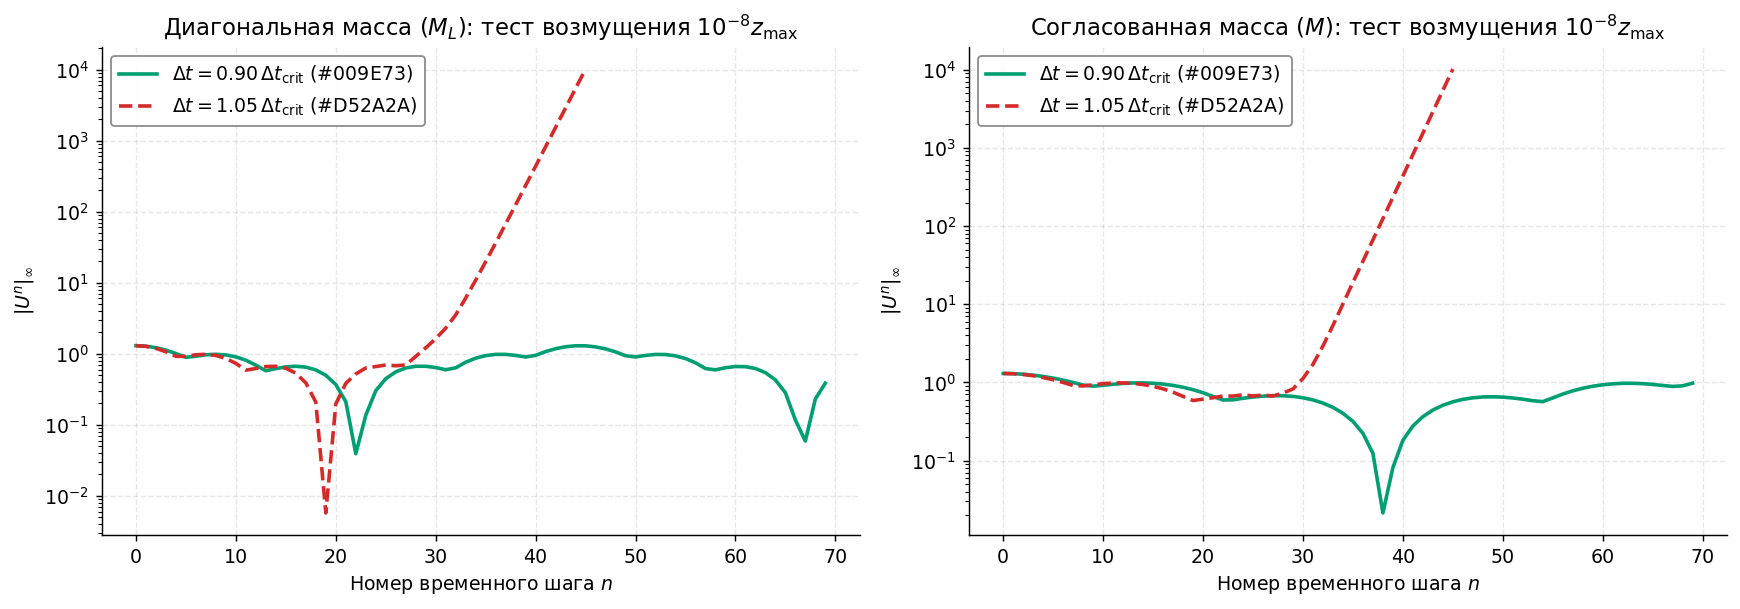

In [10]:
# Численный эксперимент со срывом устойчивости при шагах 0.9 dt_crit и 1.05 dt_crit
perturb_tests = [
    ('Диагональная масса ($M_L$)', 'lumped', dt_crit_L, 1.0 / np.diag(M_lump_y), z_max_L),
    ('Согласованная масса ($M$)', 'consistent', dt_crit_C, la.cho_factor(M_consist_y), z_max_C)
]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

for idx, (label, m_type, dt_c, inv_solver, z_max) in enumerate(perturb_tests):
    for factor, style, col in [(0.90, '-', GREEN), (1.05, '--', RED)]:
        dt_test = factor * dt_c
        
        # Начальное перемещение с добавлением возмущения 1e-8 * z_max
        u0_test = exact_solution(x_nodes_y[1:-1], 0.0) + 1e-8 * z_max
        v0_test = np.zeros_like(u0_test)
        
        U = u0_test.copy()
        V = v0_test.copy()
        
        if m_type == 'lumped':
            a = - inv_solver * (K_y @ U)
        else:
            a = - la.cho_solve(inv_solver, K_y @ U)
            
        norm_history = [np.max(np.abs(U))]
        steps_history = [0]
        
        for s in range(1, 70):
            V_half = V + 0.5 * dt_test * a
            U = U + dt_test * V_half
            if m_type == 'lumped':
                a = - inv_solver * (K_y @ U)
            else:
                a = - la.cho_solve(inv_solver, K_y @ U)
            V = V_half + 0.5 * dt_test * a
            
            val = np.max(np.abs(U))
            norm_history.append(val)
            steps_history.append(s)
            
            if val > 1e4:  # Предотвращение переполнения чисел
                break
                
        axes[idx].plot(steps_history, norm_history, style, color=col, lw=2.0,
                       label=rf'$\Delta t = {factor:.2f} \, \Delta t_{{\mathrm{{crit}}}}$ ({col})')
        
    axes[idx].set_yscale('log')
    axes[idx].set_xlabel('Номер временного шага $n$')
    axes[idx].set_ylabel(r'$\|U^n\|_\infty$')
    axes[idx].set_title(rf'{label}: тест возмущения $10^{{-8}} z_{{\max}}$')
    axes[idx].legend()

plt.tight_layout()
plt.show()

### 4.2. Ответ на ключевой вопрос желтого уровня 🟡

> **Вопрос:** *Как диагонализация массы меняет собственные частоты, допустимый шаг и накопление ошибки фазы?*

**Ответ:**

1. **Изменение собственных частот (завышение vs занижение):**
   - **Согласованная масса $M$:**  
     Построена в едином функциональном подпространстве с матрицей жесткости $K$. В силу вариационного принципа Рэлея — Ритца, дискретные собственные значения аппроксимируют непрерывный спектр оператора «сверху». Все дискретные частоты **строго завышены**:

     $$
     \omega_{h, j, C} \approx \omega_j \left( 1 + \frac{(j \pi h)^2}{24} \right) \gt \omega_j.
     $$

   - **Диагональная масса $M_L$:**  
     Стягивание массы в узлы эквивалентно искусственному локальному утяжелению узлов (увеличению инерции элементов). Это приводит к динамическому «смягчению» стержня, и все собственные частоты **строго занижаются**:

     $$
     \omega_{h, j, L} \approx \omega_j \left( 1 - \frac{(j \pi h)^2}{24} \right) \lt \omega_j.
     $$

2. **Допустимый шаг по времени (условие устойчивости Куранта):**
   - Условие устойчивости явного метода Верле: $\Delta t \le \Delta t_{\mathrm{crit}} = \frac{2}{\omega_{h, \max}}$.
   - Для согласованной массы наивысшая частота сетки равна $\omega_{h, \max, C} \approx \frac{2\sqrt{3}}{h} \approx \frac{3.464}{h}$, откуда критический шаг составляет:

     $$
     \Delta t_{\mathrm{crit}, C} \approx \frac{h}{\sqrt{3}} \approx 0.577 \, h.
     $$

   - Для диагональной массы наивысшая частота ограничена величиной $\omega_{h, \max, L} \approx \frac{2}{h}$, поэтому предельный шаг увеличивается в $\sqrt{3} \approx 1.73$ раза:

     $$
     \Delta t_{\mathrm{crit}, L} \approx h.
     $$

   *Выигрыш:* Диагонализация массы позволяет увеличить рабочий шаг интегрирования на **73%** и полностью исключает необходимость решения СЛАУ на каждом временном слое.

3. **Накопление ошибки фазы и взаимная компенсация дисперсий:**
   - Дискретизация пространственных производных порождает фазовую скорость $c_h = \omega_h / k$. Для согласованной массы волны бегут быстрее точных ($c_h \gt 1$, фазовое опережение), а для диагональной массы — медленнее ($c_h \lt 1$, фазовое отставание).
   - Временная дискретизация методом Верле также вносит дисперсию: эффективная частота схемы $\widetilde{\omega} = \frac{2}{\Delta t} \arcsin\left(\frac{\omega_h \Delta t}{2}\right) \approx \omega_h \left(1 + \frac{(\omega_h \Delta t)^2}{24}\right) \gt \omega_h$ **всегда завышает** частоту (вносит положительную фазовую ошибку).
   - Для **согласованной массы** обе ошибки складываются: волна опережает точное решение еще сильнее.
   - Для **диагональной массы** отрицательная пространственная ошибка и положительная временная ошибка имеют противоположные знаки и **взаимно компенсируют друг друга**: при приближении числа Куранта $\Delta t / h \to 1$ численная дисперсия схемы почти полностью нивелируется!

---
## 5. Выводы

1. **Зелёный уровень 🟢:**
   - Реализован метод конечных элементов для одномерного волнового уравнения с диагональной матрицей масс $M_L$ и скоростным методом Верле.
   - На последовательности сгущающихся сеток $N = 40, 80, 160$ при фиксированном отношении $\Delta t = 0.5 h$ подтвержден строгий **второй порядок точности** $\mathcal{O}(h^2)$ по пространству и времени в чебышёвской норме $e_\infty$.
   - Показано, что дискретная механическая энергия $\mathcal{H}_h(t)$ колеблется вокруг своего начального значения с амплитудой порядка $\mathcal{O}(\Delta t^2)$, не испытывая систематической вековой диссипации.
   - Обосновано, что сохранение энергии является следствием симплектичности метода Верле, но само по себе не защищает решение от линейного накопления фазовой дисперсионной ошибки.
   - Построена плавная анимация волнового движения с наложением аналитического решения.

2. **Жёлтый уровень 🟡:**
   - Решена обобщенная задача на собственные значения $K z = \omega^2 M_{\ast} z$ для согласованной и диагональной матриц масс.
   - Продемонстрирован фундаментальный вариационный эффект: согласованная масса завышает собственные частоты относительно непрерывного спектра ($\omega_{h, C} \gt \omega$), в то время как диагональная масса занижает их ($\omega_{h, L} \lt \omega$).
   - Определены предельные шаги интегрирования по критерию устойчивости Верле: $\Delta t_{\mathrm{crit}, L} \approx h$ и $\Delta t_{\mathrm{crit}, C} \approx h / \sqrt{3} \approx 0.577 h$. Диагонализация массы расширяет область устойчивости схемы по времени на 73%.
   - Численно продемонстрировано поведение центрального сигнала $u(0.5, t)$ на длительном времени: согласованная масса опережает истинную волну по фазе, а диагональная отстает от нее.
   - Эксперимент с внесением критического возмущения высшей собственной моды $10^{-8} z_{\max}$ подтвердил скачкообразный срыв устойчивости при $\Delta t = 1.05 \Delta t_{\mathrm{crit}}$ и гарантированную ограниченность при $\Delta t = 0.90 \Delta t_{\mathrm{crit}}$.